# Verificación de Datos Procesados

Este notebook **no transforma** los datos; solo **verifica** que el archivo 
`data/processed/df_long.parquet` esté correcto antes del análisis exploratorio.

Para regenerar el parquet desde el raw:
```bash
python src/data_processing.py

In [1]:
# @title Imports y carga
from pathlib import Path

import numpy as np
import pandas as pd

# Detectar raíz del repo (funciona en Colab o local)
def find_repo_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "data" / "processed" / "df_long.parquet").exists():
            return p
    raise FileNotFoundError(
        "No se encontró data/processed/df_long.parquet. "
        "Ejecuta primero: python src/data_processing.py"
    )

ROOT = find_repo_root()
PARQUET_PATH = ROOT / "data" / "processed" / "df_long.parquet"

df = pd.read_parquet(PARQUET_PATH)
print(f"Cargado: {PARQUET_PATH.relative_to(ROOT)}")
print(f"Shape: {df.shape[0]} filas × {df.shape[1]} columnas")

Cargado: data/processed/df_long.parquet
Shape: 5153 filas × 18 columnas


## 1. Estructura general

In [2]:
# @title Dtypes, head y descripción general
print("--- Dtypes ---")
print(df.dtypes)

print("\n--- Head ---")
display(df.head())

print("\n--- Describe (numéricas) ---")
display(df.describe().T)

--- Dtypes ---
id                     int64
age                  float64
bmi                  float64
female                 int64
endurancecat           int64
endurancespeed         int64
typical              float64
sprint                 int64
tempo                  int64
max                  float64
injury                 int64
footwear               int64
tiempo_ajustado_s    float64
forma_fisica         float64
dificultad           float64
distancia                str
distancia_km         float64
velocity_kmh         float64
dtype: object

--- Head ---


,id,age,bmi,female,endurancecat,endurancespeed,typical,sprint,tempo,max,injury,footwear,tiempo_ajustado_s,forma_fisica,dificultad,distancia,distancia_km,velocity_kmh
0,2,41.0,23.905970,0,1,2,23.0,1,1,28.0,1,2,1210.000000,2.0,3.0,5K,5.0,14.876033
1,3,25.0,21.640728,0,2,3,50.0,1,1,70.0,1,2,994.000061,2.0,3.0,5K,5.0,18.108651
2,4,35.0,23.592323,0,2,5,50.0,1,1,60.0,2,2,1075.000000,1.0,3.0,5K,5.0,16.744186
3,5,34.0,22.706404,0,2,3,8.0,0,0,15.0,1,2,1186.000000,1.0,3.0,5K,5.0,15.177066
4,6,45.0,42.087543,1,1,1,10.0,0,1,15.0,2,2,3240.000000,2.0,3.0,5K,5.0,5.555556



--- Describe (numéricas) ---


,count,mean,std,min,25%,50%,75%,max
id,5153.0,1081.228411,622.631523,1.000000,544.000000,1079.000000,1617.000000,2171.000000
age,5153.0,36.553367,9.857278,16.000000,29.000000,35.000000,43.000000,74.000000
bmi,5153.0,23.706333,3.060347,15.428386,21.689081,23.371714,25.204788,47.184647
female,5153.0,0.388123,0.487370,0.000000,0.000000,0.000000,1.000000,1.000000
endurancecat,5153.0,1.843392,0.654152,1.000000,1.000000,2.000000,2.000000,4.000000
endurancespeed,5153.0,3.464196,1.769613,1.000000,2.000000,3.000000,4.000000,10.000000
typical,5153.0,33.253157,17.237037,0.000000,20.000000,30.000000,45.000000,120.000000
sprint,5153.0,0.519697,0.499660,0.000000,0.000000,1.000000,1.000000,1.000000
tempo,5153.0,0.589948,0.491891,0.000000,0.000000,1.000000,1.000000,1.000000
max,5153.0,41.547435,21.690329,0.000000,25.000000,40.000000,55.000000,140.000000


## 2. Validaciones de integridad

In [5]:
# @title Aserciones
print("--- Validaciones ---")

# 1. Sin nulos en columnas clave
KEY_COLS = [
    "id", "age", "bmi", "female", "velocity_kmh",
    "distancia_km", "tiempo_ajustado_s",
]
nulos = df[KEY_COLS].isnull().sum()
assert nulos.sum() == 0, f"Hay nulos:\n{nulos[nulos > 0]}"
print("-  Sin nulos en columnas clave.")

# 2. Velocidad en rango razonable
v = df["velocity_kmh"]
assert v.min() > 0
assert v.max() < 50
print(f"-  Velocidad en [{v.min():.2f}, {v.max():.2f}] km/h.")

# 3. Fórmula de velocidad cierra
v_recalc = df["distancia_km"] / (df["tiempo_ajustado_s"] / 3600)
assert (v_recalc - v).abs().max() < 1e-9
print("-  Fórmula de velocidad verificada.")

# 4. Cobertura de distancias
DISTANCIAS = {"5K", "10K", "5mi", "10mi", "Media maratón", "Maratón"}
assert set(df["distancia"].unique()) == DISTANCIAS
print(f"-  {len(DISTANCIAS)} distancias presentes.")

# 5. Corredores y carreras
n_carreras = len(df)
n_corredores = df["id"].nunique()
assert n_corredores > 0
print(f"-  {n_carreras} carreras de {n_corredores} corredores.")

print("\nDatos procesados verificados.")

--- Validaciones ---
-  Sin nulos en columnas clave.
-  Velocidad en [5.08, 22.13] km/h.
-  Fórmula de velocidad verificada.
-  6 distancias presentes.
-  5153 carreras de 2164 corredores.

Datos procesados verificados.


## 3. Distribución de la variable objetivo

Pequeño sanity check visual. El análisis completo vive en `01_eda_y_baselines.ipynb`.

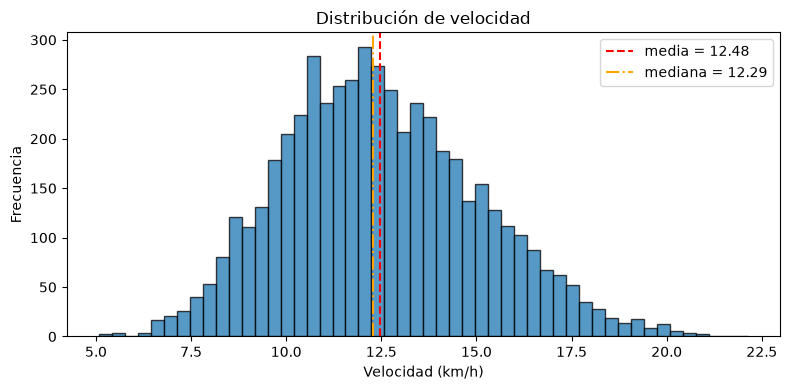

Asimetría: 0.315
Curtosis:  -0.113


In [6]:
# @title Histograma de velocidad
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["velocity_kmh"], bins=50, edgecolor="black", alpha=0.75)
ax.axvline(df["velocity_kmh"].mean(), color="red", ls="--",
           label=f"media = {df['velocity_kmh'].mean():.2f}")
ax.axvline(df["velocity_kmh"].median(), color="orange", ls="-.",
           label=f"mediana = {df['velocity_kmh'].median():.2f}")
ax.set_xlabel("Velocidad (km/h)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución de velocidad")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Asimetría: {df['velocity_kmh'].skew():.3f}")
print(f"Curtosis:  {df['velocity_kmh'].kurtosis():.3f}")

distancia
Media maratón    1444
5K               1289
Maratón           929
10K               883
10mi              313
5mi               295
Name: count, dtype: int64


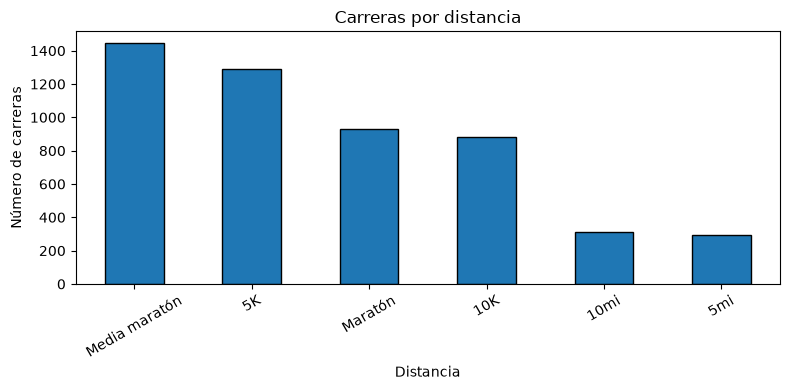

In [7]:
# @title Conteo por distancia
conteo = df["distancia"].value_counts()
print(conteo)

fig, ax = plt.subplots(figsize=(8, 4))
conteo.plot(kind="bar", ax=ax, edgecolor="black")
ax.set_xlabel("Distancia")
ax.set_ylabel("Número de carreras")
ax.set_title("Carreras por distancia")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 5. Resumen

Si todas las aserciones pasaron y las gráficas se ven razonables, los datos procesados 
están listos para el análisis exploratorio en `01_eda_y_baselines.ipynb`.